# raster-genie 01 — Smokehouse Creek: from COGs to a Genie answer

**One event, end to end.** In February 2024 the Smokehouse Creek fire burned more than a million acres of the Texas Panhandle, the largest wildfire in Texas history (NIFC and the Texas A&M Forest Service). This notebook answers the three questions an insurer or emergency manager asks first — *how much land burned, how severe was it, and how many people live there* — from raster data, with SQL, and then asks the same question of two Genie Agents:

- **Land** a perimeter, the counties it touches, Sentinel-2 scenes from before and after the fire, and WorldPop population.
- **Stack** each Sentinel-2 scene into one multi-band master COG, and register every COG in a `rasters` table through a **FILE** column.
- **Query** burn severity in plain SQL: `gbx_rst_fromfile` reads only the COG blocks the perimeter needs, `gbx_rst_nbr` and `gbx_rst_mapalgebra` build the burn index, `gbx_rst_histogram` counts the severity classes.
- **Ask** the Genie Agents the same question and compare: one computes the answer from the COGs, the other reads the saved result.

**Result:** acres burned by severity class, the people inside the perimeter, a severity map, and the Genie Agents' own answers.

---
_Tables in `geospatial_catalog.raster_genie`: `aois`, `s2_scene_assets`, `rasters`, `coverage` (view), `burn_severity_summary`._

![Raster is ready for Genie and SQL warehouses: sources, master COGs, the FILE table, GeoBrix Unity Catalog functions and the Genie Agent.](https://raw.githubusercontent.com/databrickslabs/geobrix/main/resources/images/diagrams/raster-genie/raster-genie-architecture-light.gif)

In [0]:
%run ./config_nb

geobrix 0.6.0: one wheel per runtime (+env5 / +env6); SQL functions register through databricks.labs.gbx.register(spark); the Python API is rasterx / gridx / vectorx. See https://databrickslabs.github.io/geobrix/docs/migration-0-6
geobrix: JVM level unavailable: Spark Connect session (Serverless); using the Python level (48 functions)
geobrix: SQL expression level unavailable: 5 functions (gbx_bng_cellarea, gbx_bng_eastnorthasbng, gbx_quadbin_distance, ...) need a SQL function wrapper, and SQL functions are unavailable here; using the Python level


... catalog: 'geospatial_catalog' (USE)
... schema:  'raster_genie' (CREATE / USE)
... volume:  'geospatial_catalog.raster_genie.data' (CREATE IF NOT EXISTS)


... RASTER_GENIE_DIR: '/Volumes/geospatial_catalog/raster_genie/data/raster-genie' (MKDIRS context/ fire/ s2_bands/ s2_master/ population*/)
... fire: SMOKEHOUSE CREEK (TX, 2024)  pre: 2024-01-15/2024-02-25  post: 2024-03-05/2024-03-31  MAX_CLOUD: 20  MAX_NODATA: 5
... BURN_RES_M=20.0  MAP_RES_M=80.0


... downloaders: fire_perimeters, worldpop | stac_client | gbx_file_write | prepare_cogs | ask_genie | vizx: plot_tile


In [0]:
FORCE_REBUILD = False

import time

_t_start = _t_step = time.time()
_step_no = 0


def comment_table(tbl, table_comment, columns):
    """Genie reads comments: describe a table and its columns (the FILE column included)."""
    def lit(text):  # a SQL string literal: escape the backslash and the single quote
        return "'" + text.replace("\\", "\\\\").replace("'", "\\'") + "'"

    spark.sql(f"COMMENT ON TABLE {tbl} IS {lit(table_comment)}")
    for col, text in columns.items():
        spark.sql(f"ALTER TABLE {tbl} ALTER COLUMN {col} COMMENT {lit(text)}")


def step(name):
    """One progress line per step: its number, name, how long the previous step took and the total so far."""
    global _t_step, _step_no
    now = time.time()
    _step_no += 1
    print(f"... == step {_step_no}: {name} (previous step {now - _t_step:,.0f} s, total {now - _t_start:,.0f} s)")
    _t_step = now


## 1. Why FILE + COG

A **FILE** column holds a reference to each master COG on the Volume: the table is the catalog, nothing is copied, and Unity Catalog opens the file under the caller's grants. A **Cloud Optimized GeoTIFF** keeps its pixels in 512-pixel blocks with overviews, so `gbx_rst_fromfile` fetches only the bytes a question needs: a query over one fire reads the blocks that fire covers, not the whole file.

## 2. The fire perimeter and the counties it touches

`FirePerimeterDownloader` pulls the incident's latest perimeter from the NIFC WFIGS service (EPSG:4326 GeoJSON). The TIGER cartographic boundary files give the Texas counties; we keep the ones the perimeter touches, plus the Texas outline. Together they are the `aois` table: the named areas every raster is joined to.

In [0]:
import json

import requests
from shapely import wkb
from shapely.ops import unary_union

step("fire perimeter and counties")

fire_dl = fire_perimeters.download(FIRE_NAME, FIRE_DIR, year=FIRE_YEAR, state=FIRE_STATE, spark=spark)
if not fire_dl.first()["is_out_file_valid"]:
    raise RuntimeError(f"No perimeter found for {FIRE_NAME} ({FIRE_STATE}, {FIRE_YEAR})")
fire_geoms = fire_perimeters.read(FIRE_DIR, FIRE_NAME, FIRE_YEAR, state=FIRE_STATE, spark=spark)

# The perimeter bbox, padded: it frames every Sentinel-2 and WorldPop download below.
_parts = [wkb.loads(bytes(r["geom_0"])) for r in fire_geoms.select("geom_0").collect()]
FIRE_POLY = unary_union(_parts)  # the perimeter as one shapely geometry (lon/lat)
_b = [g.bounds for g in _parts]
FIRE_BBOX = (min(x[0] for x in _b), min(x[1] for x in _b), max(x[2] for x in _b), max(x[3] for x in _b))
S2_BBOX = (
    FIRE_BBOX[0] - BBOX_PAD, FIRE_BBOX[1] - BBOX_PAD,
    FIRE_BBOX[2] + BBOX_PAD, FIRE_BBOX[3] + BBOX_PAD,
)
print(f"... perimeter bbox {tuple(round(v, 3) for v in FIRE_BBOX)}")
print(f"... download bbox  {tuple(round(v, 3) for v in S2_BBOX)} (+{BBOX_PAD} deg)")

... == step 1: fire perimeter and counties (previous step 0 s, total 0 s)
... perimeter bbox (-101.541, 35.532, -99.891, 36.059)
... download bbox  (-101.641, 35.432, -99.791, 36.159) (+0.1 deg)


In [0]:
TIGER = "https://www2.census.gov/geo/tiger/GENZ2024/shp"
for _name in ("cb_2024_us_county_500k.zip", "cb_2024_us_state_500k.zip"):
    _dst = f"{CONTEXT_DIR}/{_name}"
    if FORCE_REBUILD or not os.path.exists(_dst):
        _resp = requests.get(f"{TIGER}/{_name}", timeout=180, stream=True)
        _resp.raise_for_status()
        with open(_dst, "wb") as fh:
            for chunk in _resp.iter_content(chunk_size=1 << 20):
                fh.write(chunk)
        print(f"... TIGER {_name} -> {_dst}")

AOI_COLS = ["aoi_id", "name", "kind", "geom", "description"]

fire = fire_geoms.select(
    F.lit(FIRE_AOI_ID).alias("aoi_id"),
    F.lit("Smokehouse Creek fire").alias("name"),
    F.lit("fire").alias("kind"),
    F.expr("st_setsrid(st_geomfromwkb(geom_0), 4326)").alias("geom"),
    F.lit("Latest NIFC WFIGS perimeter of the 2024 Smokehouse Creek fire").alias("description"),
)

tx_counties = (
    spark.read.format("shapefile_gbx").load(f"{CONTEXT_DIR}/cb_2024_us_county_500k.zip")
    .filter(F.col("STATEFP") == "48")
    .select(
        F.concat(F.lit("county_"), F.col("GEOID")).alias("aoi_id"),
        F.col("NAME").alias("name"),
        F.lit("county").alias("kind"),
        F.expr("st_setsrid(st_geomfromwkb(geom_0), 4326)").alias("geom"),
        F.concat(F.col("NAME"), F.lit(" County, Texas")).alias("description"),
    )
)
# Keep the counties the perimeter touches.
touched = (
    tx_counties.alias("c")
    .join(fire.select(F.col("geom").alias("fire_geom")).alias("f"), F.expr("st_intersects(c.geom, f.fire_geom)"))
    .select(*[F.col(f"c.{c}") for c in AOI_COLS])
)
texas = (
    spark.read.format("shapefile_gbx").load(f"{CONTEXT_DIR}/cb_2024_us_state_500k.zip")
    .filter(F.col("STATEFP") == "48")
    .select(
        F.lit("tx").alias("aoi_id"),
        F.lit("Texas").alias("name"),
        F.lit("state").alias("kind"),
        F.expr("st_setsrid(st_geomfromwkb(geom_0), 4326)").alias("geom"),
        F.lit("State of Texas, TIGER cartographic boundary").alias("description"),
    )
)

aois = finalize_delta(fire.select(*AOI_COLS).unionByName(touched).unionByName(texas), "aois", do_display=False)
aois.select("aoi_id", "name", "kind", "description").orderBy("kind", "name").display()

... table aois exists (skip; FORCE_REBUILD=False)


aoi_id,name,kind,description
county_48065,Carson,county,"Carson County, Texas"
county_48179,Gray,county,"Gray County, Texas"
county_48211,Hemphill,county,"Hemphill County, Texas"
county_48233,Hutchinson,county,"Hutchinson County, Texas"
county_48295,Lipscomb,county,"Lipscomb County, Texas"
county_48393,Roberts,county,"Roberts County, Texas"
county_48483,Wheeler,county,"Wheeler County, Texas"
smokehouse_creek,Smokehouse Creek fire,fire,Latest NIFC WFIGS perimeter of the 2024 Smokehouse Creek fire
tx,Texas,state,"State of Texas, TIGER cartographic boundary"


## 3. Sentinel-2: the scenes, windowed and stacked

`StacClient.search` queries Microsoft Planetary Computer's `sentinel-2-l2a` collection over the padded perimeter bbox for two windows, before and after the fire. A scene is a candidate when its scene-level cloud cover is at most `MAX_CLOUD` percent and its no-data share is at most `MAX_NODATA` percent. That no-data figure is for the whole MGRS tile, so it is a screen for scenes cut by the satellite's orbit edge, not a measure of the perimeter; a scene with no figure at all is kept, and the coverage check on the result (section 7) is what judges it. From the candidates we pick **one scene per MGRS tile** with three rules:

- **Few dates.** The pre scenes share as few dates as possible across the tiles (the date that serves most tiles first, ties to the date closest to the fire), and so do the post scenes. Tiles on different satellite orbits are imaged on different days, so one date for all tiles is often not possible; the table below the cell lists the date and orbit chosen for each tile.
- **Same orbit.** A tile's post scene is on the same relative orbit as its pre scene wherever that orbit has a clean candidate, so the two views have the same angle and the difference between them is the ground.
- **Least cloud.** Within a tile and a day the least-cloud scene wins. A tie means the same whole percent of cloud, and then the exact figure decides.

`PRE_WINDOW` is wider than `POST_WINDOW` because the clean pre-fire scenes of some tiles are few: a tile can have a cloudy February and a cut-off orbit edge, and the window must reach back far enough to hold one clean scene for every tile that meets the perimeter. `StacClient.download` then fetches the seven bands we need (B02, B03, B04, B08, B11, B12 and the scene classification SCL) **windowed to the padded bbox**: only that part of each scene crosses the network.

In [0]:
import sys

from pyspark.sql.types import DoubleType, StringType, StructField, StructType
from shapely.geometry import box

# choose_scene_pairs and stack_scene live in lakeflow/land/scenes.py, beside this notebook.
_lakeflow = os.path.join(os.getcwd(), "lakeflow")
if not os.path.exists(os.path.join(_lakeflow, "land", "scenes.py")):
    raise FileNotFoundError(
        f"lakeflow/land/scenes.py was not found next to this notebook ({os.getcwd()}). "
        "Fix: open this series from a Git folder, or copy the lakeflow/ folder next to the notebooks."
    )
sys.path.insert(0, _lakeflow)
from land.scenes import STACK_VERSION, S2_BANDS, boa_offset_for, choose_scene_pairs, is_current, stack_scene, table_stack_version

step("Sentinel-2 scene search")
SCENE_ASSETS = "s2_scene_assets"
S2_BAND_NAMES = ["B02", "B03", "B04", "B08", "B11", "B12", "SCL"]

# The search area: the padded bbox as a GeoJSON polygon.
_x0, _y0, _x1, _y1 = S2_BBOX
aoi_polygon = spark.createDataFrame(
    [(json.dumps({"type": "Polygon", "coordinates": [[[_x0, _y0], [_x1, _y0], [_x1, _y1], [_x0, _y1], [_x0, _y0]]]}),)],
    ["geojson"],
)


def search_window(window):
    """One window's STAC search: the hrefs of the band assets, and one candidate row per scene over the perimeter."""
    found = stac_client.search(aoi_polygon, geojson_col="geojson", collections=["sentinel-2-l2a"], datetime=window)
    items = (
        found.dropDuplicates(["item_id"])
        .select(
            "item_id", "date", "item_bbox",
            F.col("item_properties")["eo:cloud_cover"].cast("double").alias("cloud_pct"),
            F.col("item_properties")["s2:nodata_pixel_percentage"].cast("double").alias("nodata_pct"),
            F.col("item_properties")["s2:processing_baseline"].alias("baseline"),
            F.regexp_extract("item_id", r"_T(\d{2}[A-Z]{3})_", 1).alias("mgrs_tile"),
            F.regexp_extract("item_id", r"_R(\d{3})_", 1).alias("orbit"),
        )
        .collect()
    )
    rows = [r.asDict() for r in items if r["item_bbox"] and box(*r["item_bbox"]).intersects(FIRE_POLY)]
    return found, rows


if FORCE_REBUILD or not spark.catalog.tableExists(SCENE_ASSETS):
    pre_found, pre_rows = search_window(PRE_WINDOW)
    post_found, post_rows = search_window(POST_WINDOW)
    picked = choose_scene_pairs(pre_rows, post_rows, MAX_CLOUD, MAX_NODATA)
    if not picked["pre"]:
        raise RuntimeError(f"No tile has a clean pre and post scene. Fix: widen PRE_WINDOW/POST_WINDOW or raise MAX_CLOUD ({MAX_CLOUD}).")
    if picked["dropped"]:
        print(f"... no clean pre and post scene for tile(s) {', '.join(picked['dropped'])}: left out")
    if picked["orbit_mismatch"]:
        print(f"... post scene on another orbit than the pre scene for tile(s) {', '.join(picked['orbit_mismatch'])}")
    _unknown = [r["item_id"] for p in ("pre", "post") for r in picked[p].values() if r["nodata_pct"] is None]
    if _unknown:
        print(f"... {len(_unknown)} chosen scene(s) have no STAC no-data figure; the coverage check in section 7 judges them")
    meta_schema = StructType([
        StructField("item_id", StringType()), StructField("phase", StringType()), StructField("mgrs_tile", StringType()),
        StructField("date", StringType()), StructField("orbit", StringType()), StructField("cloud_pct", DoubleType()),
        StructField("nodata_pct", DoubleType()), StructField("baseline", StringType()),
    ])
    meta = spark.createDataFrame(
        [(r["item_id"], phase, r["mgrs_tile"], r["date"], r["orbit"], r["cloud_pct"], r["nodata_pct"], r["baseline"])
         for phase in ("pre", "post") for r in picked[phase].values()],
        meta_schema,
    )
    hrefs = (
        pre_found.unionByName(post_found)
        .filter(F.col("asset_name").isin(*S2_BAND_NAMES))
        .select("item_id", "asset_name", "href")
        .dropDuplicates(["item_id", "asset_name"])
    )
    finalize_delta(hrefs.join(meta, "item_id"), SCENE_ASSETS, do_display=False)
    comment_table(SCENE_ASSETS, "One row per Sentinel-2 band file downloaded for the Smokehouse Creek fire: the STAC item, the band, the scene date, the tile, the relative orbit, cloud cover and processing baseline.", {
        "item_id": "Planetary Computer STAC item id of the Sentinel-2 scene; the relative orbit is the digits after _R, as in _R012_",
        "asset_name": "Band or asset name of the file, for example B08, B12 or SCL",
        "href": "Source URL of the band file",
        "phase": "pre (scene before the fire) or post (scene after the fire)",
        "mgrs_tile": "Military Grid Reference System tile of the scene, for example 14SLE",
        "date": "Acquisition date and time of the scene as text; the first 10 characters are the date",
        "orbit": "Relative orbit number of the satellite pass, as text",
        "cloud_pct": "Scene-level cloud cover in percent",
        "nodata_pct": "Share of the tile with no data, in percent",
        "baseline": "Sentinel-2 processing baseline, for example 05.10",
    })
else:
    print(f"... {SCENE_ASSETS} exists; skipping the STAC search (FORCE_REBUILD=False)")

(
    spark.table(SCENE_ASSETS)
    .select("phase", "mgrs_tile", "item_id", "date", "orbit", "cloud_pct", "nodata_pct", "baseline")
    .distinct()
    .orderBy("mgrs_tile", "phase")
    .display()
)


... == step 2: Sentinel-2 scene search (previous step 34 s, total 34 s)
... s2_scene_assets exists; skipping the STAC search (FORCE_REBUILD=False)


phase,mgrs_tile,item_id,date,orbit,cloud_pct,nodata_pct,baseline
post,14SKE,S2A_MSIL2A_20240310T173131_R055_T14SKE_20240311T102744,2024-03-10,055,0.031204,0.0,05.10
pre,14SKE,S2B_MSIL2A_20240224T173319_R055_T14SKE_20240224T231626,2024-02-24,055,4.257693,0.0,05.10
post,14SLE,S2B_MSIL2A_20240312T172019_R012_T14SLE_20240312T231414,2024-03-12,012,0.003636,3e-06,05.10
pre,14SLE,S2A_MSIL2A_20240127T172601_R012_T14SLE_20240127T223835,2024-01-27,012,0.003198,0.0,05.10
post,14SLF,S2B_MSIL2A_20240312T172019_R012_T14SLF_20240312T231119,2024-03-12,012,0.008104,3.499398,05.10
pre,14SLF,S2A_MSIL2A_20240127T172601_R012_T14SLF_20240127T223859,2024-01-27,012,0.006434,3.516853,05.10
post,14SME,S2B_MSIL2A_20240312T172019_R012_T14SME_20240312T231747,2024-03-12,012,0.000833,0.0,05.10
pre,14SME,S2A_MSIL2A_20240127T172601_R012_T14SME_20240127T223857,2024-01-27,012,9.862656,1.3e-05,05.10


In [0]:
step("download the band files")
# Download the chosen bands, windowed to the padded bbox. Files that are already valid on the
# Volume are skipped, so a re-run downloads nothing new.
downloads = stac_client.download(
    spark.table(SCENE_ASSETS).select("item_id", "asset_name", "href"),
    S2_RAW_DIR,
    bbox=list(S2_BBOX),
    bbox_crs="EPSG:4326",
).select("item_id", "asset_name", "out_file_path", "out_file_sz", "is_out_file_valid").collect()

failed = [r for r in downloads if not r["is_out_file_valid"]]
print(f"... {len(downloads) - len(failed)} of {len(downloads)} band files valid in {S2_RAW_DIR}")
if failed:
    raise RuntimeError(f"{len(failed)} band downloads failed, e.g. {failed[0]['item_id']} {failed[0]['asset_name']}")

... == step 3: download the band files (previous step 2 s, total 36 s)
... 56 of 56 band files valid in /Volumes/geospatial_catalog/raster_genie/data/raster-genie/s2_bands


Now stack each scene. `stack_scene` (in `lakeflow/land/scenes.py`) writes **one master COG per scene**: the seven bands on the 10 m grid of B04 (the 20 m bands B11, B12 and SCL are resampled, bilinear for reflectance and nearest for SCL), 512-pixel blocks, average overviews at 2/4/8/16, GeoBrix's own compression options, nodata 0, and the band names as band descriptions. Reflectance has Sentinel-2's +1000 processing offset removed first, so the indices are taken on true reflectance.

**The scene is cloud-masked once, when the master COG is written.** At the native 10 m, every reflectance pixel whose SCL class is no data (0), saturated (1), cloud shadow (3), cloud (8, 9), thin cirrus (10) or snow (11) is set to nodata. That is good data engineering: the mask is applied once, at the finest resolution where SCL is accurate, and every query below reads clean pixels and needs no SCL logic at all. GDAL's average skips nodata, so a masked pixel does not drag a coarse overview pixel toward zero. SCL stays in the file as band 7 for reference, but its overviews are averages of class ids and mean nothing: read SCL at full resolution only. The file carries no internal mask band: nodata is the only validity signal, which is what the Unity Catalog windowed reader plans for. The cell prints the masked share of each scene as it is written.

Each master COG is stamped with the tag `GBX_STACK_VERSION`. A re-run skips a file that carries the current version and rebuilds one that is missing or has an older version, so a master written before the cloud mask is never reused.

In [0]:
import datetime

import rasterio

step("stack the master COGs")

band_files = {}
for r in downloads:
    band_files.setdefault(r["item_id"], {})[r["asset_name"]] = r["out_file_path"]

scene_rows = (
    spark.table(SCENE_ASSETS)
    .select("item_id", "phase", "mgrs_tile", "date", "cloud_pct", "baseline")
    .distinct()
    .orderBy("phase", "mgrs_tile")
    .collect()
)

masters = []  # one record per scene master COG
rebuilt = []  # the master COGs written in this run
for s in scene_rows:
    day = s["date"][:10]
    asset_id = f"s2_{s['mgrs_tile']}_{day.replace('-', '')}"
    out = f"{S2_MASTER_DIR}/{asset_id}.tif"
    stats = {}
    if FORCE_REBUILD or not is_current(out):  # missing, or stacked by an older version (no GBX_STACK_VERSION tag)
        t0 = time.time()
        stack_scene(band_files[s["item_id"]], out, bands=S2_BANDS, ref="B04", boa_offset=boa_offset_for(s["baseline"]), stats=stats)
        rebuilt.append(asset_id)
        print(f"... stacked {asset_id} ({s['phase']}, scene cloud {s['cloud_pct']:.1f}%) in {time.time() - t0:,.0f} s: "
              f"SCL masked {stats['masked_pct']:.2f}% of {stats['data_px']:,} data pixels")
    else:
        print(f"... {asset_id} exists (stack version {STACK_VERSION}; skip)")
    with rasterio.open(out) as ds:
        km2 = ds.width * ds.height * abs(ds.res[0] * ds.res[1]) / 1e6
    masters.append(
        dict(asset_id=asset_id, day=datetime.date.fromisoformat(day), cloud_pct=float(s["cloud_pct"]),
             path=out, bytes=os.path.getsize(out), km2=km2,
             masked_px=stats.get("masked_px"), data_px=stats.get("data_px"))
    )
print(f"... {len(masters)} Sentinel-2 master COGs in {S2_MASTER_DIR}")
_counted = [m for m in masters if m["data_px"]]
if _counted:
    print(f"... SCL masked {100 * sum(m['masked_px'] for m in _counted) / sum(m['data_px'] for m in _counted):.2f}% "
          f"of the data pixels of {len(_counted)} scenes written in this run")

# A rebuilt master changes the bytes, size and checksum behind its FILE reference, so what is derived from it is
# rebuilt too: the rasters table (FILE column), the coverage view and burn_severity_summary. The rasters table
# carries the stack version it was written under, so a run that stopped half way is still detected next time.
RASTERS = f"{catalog_name}.{schema_name}.rasters"


rasters_stale = bool(rebuilt) or (spark.catalog.tableExists(RASTERS) and table_stack_version(spark, RASTERS) != str(STACK_VERSION))
if rasters_stale:
    print(f"... {len(rebuilt)} master COG(s) written in this run{': ' + ', '.join(rebuilt) if rebuilt else ''}; "
          f"{RASTERS} (FILE size and checksum), the coverage view and burn_severity_summary are rebuilt from the new files below")
    spark.sql("DROP TABLE IF EXISTS burn_severity_summary")

... == step 4: stack the master COGs (previous step 30 s, total 66 s)
... stacked s2_14SKE_20240310 (post, scene cloud 0.0%) in 45 s: SCL masked 0.04% of 39,058,236 data pixels
... stacked s2_14SLE_20240312 (post, scene cloud 0.0%) in 102 s: SCL masked 0.00% of 86,533,376 data pixels
... stacked s2_14SLF_20240312 (post, scene cloud 0.0%) in 22 s: SCL masked 0.01% of 16,063,740 data pixels
... stacked s2_14SME_20240312 (post, scene cloud 0.0%) in 27 s: SCL masked 0.00% of 22,768,209 data pixels
... stacked s2_14SKE_20240224 (pre, scene cloud 4.3%) in 44 s: SCL masked 0.03% of 39,058,236 data pixels
... stacked s2_14SLE_20240127 (pre, scene cloud 0.0%) in 94 s: SCL masked 0.03% of 86,533,380 data pixels
... stacked s2_14SLF_20240127 (pre, scene cloud 0.0%) in 21 s: SCL masked 0.00% of 16,063,740 data pixels
... stacked s2_14SME_20240127 (pre, scene cloud 9.9%) in 27 s: SCL masked 0.00% of 22,768,209 data pixels
... 8 Sentinel-2 master COGs in /Volumes/geospatial_catalog/raster_genie/data

## 4. WorldPop population

WorldPop's 2020 constrained population grid for the USA is a single national GeoTIFF. `WorldPopDownloader` windows it to the same padded bbox; where the server cannot serve byte ranges it fetches the national file once into `POP_CACHE_DIR` first, and every later call windows that local copy. `prepare_cogs` rewrites the window as a master COG in `population/`: the same layout as the Sentinel-2 scenes, so one table catalogs both.

In [0]:
step("WorldPop population")
pop_dl = worldpop.download(S2_BBOX, POP_RAW_DIR, spark=spark, cache_dir=POP_CACHE_DIR).first()
if not pop_dl["is_out_file_valid"]:
    raise RuntimeError("WorldPop window does not overlap the download bbox")
pop_summary = prepare_cogs(
    pop_dl["out_file_path"], POP_DIR, blocksize=512, compress="auto", bigtiff="IF_SAFER", skip_if_exists=not FORCE_REBUILD
)
pop_cog = pop_summary["results"][0]["output_path"]
if pop_cog is None:
    raise RuntimeError(f"population COG failed: {pop_summary['results'][0]['status']}")
print(f"... population master COG: {pop_cog} ({os.path.getsize(pop_cog) / 1e6:,.1f} MB)")

... == step 5: WorldPop population (previous step 391 s, total 457 s)
[1/1] skipped usa_ppp_2020_constrained_e5748c95.tif -> usa_ppp_2020_constrained_e5748c95.tif.cog (0 left, 0.08s, peak 1453 MiB)
done: 0 ok, 1 skipped, 0 error of 1 (peak 1453 MiB, 0.09s total)
... population master COG: /Volumes/geospatial_catalog/raster_genie/data/raster-genie/population/usa_ppp_2020_constrained_e5748c95.tif.cog (0.2 MB)


## 5. Land the COGs as a FILE table

One row per master COG: its product, tier, area, date, band order, source and licence, and the **FILE EXTERNAL** column `file` that points at the COG on the Volume. All of these are marked **enhanced**, the tier for focus areas and events. We read the technical metadata from the COG itself with SQL before writing: a header-only tile gives the CRS, pixel size and bounding box (`gbx_rst_srid`, `gbx_rst_pixelheight`, `gbx_rst_boundingbox`, reprojected to a `GEOMETRY(4326)` footprint with `st_transform`), and `valid_pct` is the share of data pixels read from a coarse overview, so landing never decodes a full scene.

In [0]:
step("land the COGs as a FILE table")
if FORCE_REBUILD or rasters_stale or not spark.catalog.tableExists(RASTERS):
    s2_source = "Sentinel-2 L2A, Microsoft Planetary Computer"
    s2_license = "Copernicus Sentinel data: free, full and open"
    rows = [
        (m["asset_id"], "s2_l2a", "enhanced", FIRE_AOI_ID, m["day"], list(S2_BANDS),
         s2_source, s2_license, m["cloud_pct"], m["path"], 160.0)
        for m in masters
    ]
    rows.append(
        ("pop_worldpop_2020_" + FIRE_AOI_ID, "population", "enhanced", FIRE_AOI_ID, datetime.date(2020, 1, 1),
         ["population"], "WorldPop 2020 constrained population, USA (people per pixel)", "CC BY 4.0",
         None, pop_cog, None)
    )
    landing_schema = StructType([
        StructField("asset_id", StringType()), StructField("product", StringType()),
        StructField("tier", StringType()), StructField("aoi_id", StringType()),
        StructField("acquired_date", DateType()), StructField("bands", ArrayType(StringType())),
        StructField("source", StringType()), StructField("license", StringType()),
        StructField("cloud_pct", DoubleType()), StructField("path", StringType()),
        StructField("preview_res", DoubleType()),  # pixel size of the coarse overview read for valid_pct
    ])
    landing = spark.createDataFrame(rows, landing_schema)

    # t: a header-only tile (CRS, pixel size, bounds). preview: a coarse overview read (valid pixels).
    (
        landing
        .withColumn("t", rx.rst_fromfile(F.col("path")))
        .withColumn("preview", F.expr("gbx_rst_fromfile(path, 'GTiff', NULL, NULL, preview_res)"))
        .createOrReplaceTempView("landing_tiles")
    )
    rasters_df = spark.sql("""
        SELECT asset_id, product, tier, aoi_id, acquired_date, bands,
               concat('EPSG:', CAST(gbx_rst_srid(t) AS STRING)) AS crs,
               CASE WHEN gbx_rst_srid(t) = 4326
                    THEN abs(gbx_rst_pixelheight(t)) * 111320.0
                    ELSE abs(gbx_rst_pixelwidth(t)) END AS resolution_m,
               st_transform(st_setsrid(st_geomfromwkb(gbx_rst_boundingbox(t)), gbx_rst_srid(t)), 4326) AS footprint,
               round(100.0 * gbx_rst_pixelcount(preview)[0] / (gbx_rst_width(preview) * gbx_rst_height(preview)), 1) AS valid_pct,
               cloud_pct, source, license, path
        FROM landing_tiles
    """)
    gbx_file_write(rasters_df, RASTERS, file_mode="external", file_col="file", overwrite=True)
    spark.sql(f"ALTER TABLE {RASTERS} SET TBLPROPERTIES ('gbx.stack_version' = '{STACK_VERSION}')")
else:
    print(f"... {RASTERS} exists and is current (skip; FORCE_REBUILD=False)")

spark.table(RASTERS).select(
    "asset_id", "product", "tier", "acquired_date", "bands", "crs", "resolution_m", "valid_pct", "cloud_pct", "file"
).orderBy("product", "acquired_date").display()

... == step 6: land the COGs as a FILE table (previous step 4 s, total 461 s)


asset_id,product,tier,acquired_date,bands,crs,resolution_m,valid_pct,cloud_pct,file
pop_worldpop_2020_smokehouse_creek,population,enhanced,2020-01-01,"[""population""]",EPSG:4326,92.7666662956,0.6,null,"{""uri"":""dbfs:/Volumes/geospatial_catalog/raster_genie/data/raster-genie/population/usa_ppp_2020_constrained_e5748c95.tif.cog"",""size"":157869,""content_type"":""application/octet-stream"",""checksum"":""ETAG:47afb444f3714651277fa0ce19a155be""}"
s2_14SLF_20240127,s2_l2a,enhanced,2024-01-27,"[""B02"", ""B03"", ""B04"", ""B08"", ""B11"", ""B12"", ""SCL""]",EPSG:32614,10.0,100.0,0.006434,"{""uri"":""dbfs:/Volumes/geospatial_catalog/raster_genie/data/raster-genie/s2_master/s2_14SLF_20240127.tif"",""size"":164125794,""content_type"":""binary/octet-stream"",""checksum"":""ETAG:44d96420706f66d5545b46e3928adb8a-8""}"
s2_14SME_20240127,s2_l2a,enhanced,2024-01-27,"[""B02"", ""B03"", ""B04"", ""B08"", ""B11"", ""B12"", ""SCL""]",EPSG:32614,10.0,100.0,9.862656,"{""uri"":""dbfs:/Volumes/geospatial_catalog/raster_genie/data/raster-genie/s2_master/s2_14SME_20240127.tif"",""size"":240375433,""content_type"":""binary/octet-stream"",""checksum"":""ETAG:1a7a469ba782fc2ac686f894f062cf60-12""}"
s2_14SLE_20240127,s2_l2a,enhanced,2024-01-27,"[""B02"", ""B03"", ""B04"", ""B08"", ""B11"", ""B12"", ""SCL""]",EPSG:32614,10.0,100.0,0.003198,"{""uri"":""dbfs:/Volumes/geospatial_catalog/raster_genie/data/raster-genie/s2_master/s2_14SLE_20240127.tif"",""size"":904149948,""content_type"":""binary/octet-stream"",""checksum"":""ETAG:26200dc7bccc17d1fab120c149cc4bad-44""}"
s2_14SKE_20240224,s2_l2a,enhanced,2024-02-24,"[""B02"", ""B03"", ""B04"", ""B08"", ""B11"", ""B12"", ""SCL""]",EPSG:32614,10.0,100.0,4.257693,"{""uri"":""dbfs:/Volumes/geospatial_catalog/raster_genie/data/raster-genie/s2_master/s2_14SKE_20240224.tif"",""size"":397502726,""content_type"":""binary/octet-stream"",""checksum"":""ETAG:bf7aee6db0ce917270c48470bf3e93ec-19""}"
s2_14SKE_20240310,s2_l2a,enhanced,2024-03-10,"[""B02"", ""B03"", ""B04"", ""B08"", ""B11"", ""B12"", ""SCL""]",EPSG:32614,10.0,100.0,0.031204,"{""uri"":""dbfs:/Volumes/geospatial_catalog/raster_genie/data/raster-genie/s2_master/s2_14SKE_20240310.tif"",""size"":402426820,""content_type"":""binary/octet-stream"",""checksum"":""ETAG:262a4a3bbb0f8476b5a827117c66a6bf-20""}"
s2_14SLE_20240312,s2_l2a,enhanced,2024-03-12,"[""B02"", ""B03"", ""B04"", ""B08"", ""B11"", ""B12"", ""SCL""]",EPSG:32614,10.0,100.0,0.003636,"{""uri"":""dbfs:/Volumes/geospatial_catalog/raster_genie/data/raster-genie/s2_master/s2_14SLE_20240312.tif"",""size"":908456029,""content_type"":""binary/octet-stream"",""checksum"":""ETAG:ed746bd458a7885c9f8b8faed099ed0a-44""}"
s2_14SLF_20240312,s2_l2a,enhanced,2024-03-12,"[""B02"", ""B03"", ""B04"", ""B08"", ""B11"", ""B12"", ""SCL""]",EPSG:32614,10.0,100.0,0.008104,"{""uri"":""dbfs:/Volumes/geospatial_catalog/raster_genie/data/raster-genie/s2_master/s2_14SLF_20240312.tif"",""size"":164888462,""content_type"":""binary/octet-stream"",""checksum"":""ETAG:ca1dd1b18331a3bbed82a850f01f2fe3-8""}"
s2_14SME_20240312,s2_l2a,enhanced,2024-03-12,"[""B02"", ""B03"", ""B04"", ""B08"", ""B11"", ""B12"", ""SCL""]",EPSG:32614,10.0,100.0,0.000833,"{""uri"":""dbfs:/Volumes/geospatial_catalog/raster_genie/data/raster-genie/s2_master/s2_14SME_20240312.tif"",""size"":243346356,""content_type"":""binary/octet-stream"",""checksum"":""ETAG:82b4634936727b5bde805a9ba7cebf81-12""}"


In [0]:
# Genie reads the comments: describe the tables and their columns.
comment_table(RASTERS, "One row per master COG: Sentinel-2 L2A scenes and WorldPop population, each registered through a FILE column.", {
    "asset_id": "Unique id of the master COG",
    "product": "s2_l2a (Sentinel-2 L2A imagery) or population (WorldPop people per pixel); no elevation or land cover is held yet",
    "tier": "standard (all of Texas) or enhanced (focus areas and events)",
    "aoi_id": "The area (aois.aoi_id) the asset was landed for",
    "acquired_date": "Acquisition date of the scene; the reference year for population",
    "bands": "Band names in band order; the position in this array is the 1-based band index",
    "crs": "Coordinate reference system of the COG",
    "resolution_m": "Native pixel size in metres",
    "footprint": "Extent of the COG as a GEOMETRY(4326)",
    "valid_pct": "Percent of pixels that hold data (not nodata)",
    "cloud_pct": "Scene-level cloud cover in percent (Sentinel-2 only)",
    "source": "Where the data comes from",
    "license": "Licence of the data",
    "path": "Volume path of the COG",
    "file": "FILE EXTERNAL reference to the COG; pass it to gbx_rst_fromfile",
})
comment_table(f"{catalog_name}.{schema_name}.aois", "Named areas: the fire perimeter, the Texas counties it touches and the Texas outline.", {
    "aoi_id": "Unique id of the area",
    "name": "Display name",
    "kind": "fire, county or state",
    "geom": "Boundary as a GEOMETRY(4326)",
    "description": "What the area is",
})

In [0]:
# What landing produced, and what that means at scale.
s2_gb = sum(m["bytes"] for m in masters) / 1e9
s2_km2 = sum(m["km2"] for m in masters)
n_assets = spark.table(RASTERS).count()
print(f"... {n_assets} assets in {RASTERS}: {len(masters)} Sentinel-2 scenes ({s2_gb:,.2f} GB over about {s2_km2:,.0f} km2) + 1 population COG")
print(
    f"... at this density, one Sentinel-2 pass over all of Texas (695,662 km2) is about {s2_gb / s2_km2 * 695_662 / 1e3:,.1f} TB "
    "of master COGs, and a year of quarterly passes about four times that: the same table, the same query."
)

... 9 assets in geospatial_catalog.raster_genie.rasters: 8 Sentinel-2 scenes (3.43 GB over about 32,885 km2) + 1 population COG
... at this density, one Sentinel-2 pass over all of Texas (695,662 km2) is about 0.1 TB of master COGs, and a year of quarterly passes about four times that: the same table, the same query.


## 6. The `coverage` view

What do we hold, where, at what resolution and how recent? `coverage` answers that per product, tier and area by joining each COG's footprint to the `aois`. A data-product owner can ask it the first question of any engagement.

In [0]:
step("coverage view")
spark.sql("""
    CREATE OR REPLACE VIEW coverage (
      product COMMENT 's2_l2a (Sentinel-2 L2A imagery) or population (WorldPop people per pixel); no elevation or land cover is held yet',
      tier COMMENT 'standard (all of Texas) or enhanced (focus areas and events)',
      aoi_id COMMENT 'Unique id of the area (aois.aoi_id)',
      aoi_name COMMENT 'Display name of the area',
      aoi_kind COMMENT 'fire, county or state',
      best_resolution_m COMMENT 'Finest pixel size held, in metres (the best resolution)',
      first_date COMMENT 'Earliest acquisition date held',
      last_date COMMENT 'Latest acquisition date held (how recent the data is)',
      assets COMMENT 'Number of master COG files that intersect the area',
      mean_valid_pct COMMENT 'Mean percent of pixels that hold data (not nodata) across those files'
    )
    COMMENT 'What raster data we hold: one row per product, tier and area, with the best resolution, date range, asset count and mean valid percent.'
    AS
    SELECT r.product, r.tier, a.aoi_id, a.name AS aoi_name, a.kind AS aoi_kind,
           min(r.resolution_m) AS best_resolution_m,
           min(r.acquired_date) AS first_date,
           max(r.acquired_date) AS last_date,
           count(*) AS assets,
           round(avg(r.valid_pct), 1) AS mean_valid_pct
    FROM rasters r
    JOIN aois a ON st_intersects(r.footprint, a.geom)
    GROUP BY r.product, r.tier, a.aoi_id, a.name, a.kind
""")
spark.table("coverage").orderBy("aoi_kind", "aoi_name", "product").display()

... == step 7: coverage view (previous step 106 s, total 567 s)


product,tier,aoi_id,aoi_name,aoi_kind,best_resolution_m,first_date,last_date,assets,mean_valid_pct
population,enhanced,county_48065,Carson,county,92.7666662956,2020-01-01,2020-01-01,1,0.6
s2_l2a,enhanced,county_48065,Carson,county,10.0,2024-01-27,2024-03-12,4,100.0
population,enhanced,county_48179,Gray,county,92.7666662956,2020-01-01,2020-01-01,1,0.6
s2_l2a,enhanced,county_48179,Gray,county,10.0,2024-01-27,2024-03-12,2,100.0
population,enhanced,county_48211,Hemphill,county,92.7666662956,2020-01-01,2020-01-01,1,0.6
s2_l2a,enhanced,county_48211,Hemphill,county,10.0,2024-01-27,2024-03-12,6,100.0
population,enhanced,county_48233,Hutchinson,county,92.7666662956,2020-01-01,2020-01-01,1,0.6
s2_l2a,enhanced,county_48233,Hutchinson,county,10.0,2024-01-27,2024-03-12,6,100.0
population,enhanced,county_48295,Lipscomb,county,92.7666662956,2020-01-01,2020-01-01,1,0.6
s2_l2a,enhanced,county_48295,Lipscomb,county,10.0,2024-01-27,2024-03-12,6,100.0


## 7. Burn severity in plain SQL

The classes follow the standard dNBR table (Key & Benson, 2006, *FIREMON*, USDA Forest Service RMRS-GTR-164, as published by USGS):

| dNBR | Class | Severity |
|---|---|---|
| below 0.1 | 1 | Unburned |
| 0.1 to 0.27 | 2 | Low |
| 0.27 to 0.44 | 3 | Moderate-low |
| 0.44 to 0.66 | 4 | Moderate-high |
| 0.66 and above | 5 | High |

Key & Benson also list two regrowth classes below -0.1 (enhanced regrowth, high and low); they are folded into class 1, Unburned, here. The table was written for forest burns. Winter scenes of a grass and brush landscape are a different case: the sun is low, the grass is dormant, and a grass fire changes NBR far less than a forest fire does, so expect most of such a fire in the lower classes. The classes then say more about relative severity than about absolute fuel loss.

The query is one SQL statement over the `rasters`, `s2_scene_assets` and `aois` tables:

1. **Pair** each MGRS tile's pre and post scene whose footprints both meet the perimeter (the tile is part of the `asset_id`; the relative orbit comes from `s2_scene_assets`).
2. **Read** only the perimeter from each scene with `gbx_rst_fromfile(file, 'GTiff', <perimeter>, 'EPSG:4326', <resolution>)`: the geometry clips the window and the resolution picks the overview, so only the COG blocks the perimeter touches are fetched.
3. **Index** each read with `gbx_rst_nbr(tile, nir, swir)`, the normalized burn ratio `(NIR - SWIR) / (NIR + SWIR)`. The band numbers are looked up from the `bands` column: NIR is B08, SWIR is B12. The reads are already cloud-masked (the masks went in when the master COGs were written), and `gbx_rst_nbr` leaves NoData where either band is nodata.
4. **Difference** them with `gbx_rst_mapalgebra`: dNBR = pre NBR - post NBR.
5. **Offset** each tile's dNBR by the mean dNBR of its unburned reference ring (next paragraph), with one more `gbx_rst_mapalgebra`.
6. **Classify** dNBR into the five classes with a second `gbx_rst_mapalgebra`, and **merge** the tiles with `gbx_rst_merge`, so the overlap between neighbouring MGRS tiles is counted once.
7. **Count** the pixels per class with `gbx_rst_histogram`, and turn pixels into area with the tile's own pixel size. `pct_of_valid_pixels` is each class's share of the pixels that hold data inside the perimeter.

**Why an offset.** The pre and post scenes of a tile are weeks apart and, between tiles, on different dates and orbits, so even ground that did not burn has a dNBR that is not zero: the vegetation, its moisture and the sun are not the same on the two dates. The standard remedy, used in the MTBS burn-severity method and recommended by Key & Benson, is to measure that background on ground that did not burn and subtract it from the whole scene pair. Here the **reference ring** is the band from 1 km to 5 km outside the perimeter, cut to each tile's footprint and read exactly like the main read, so it is cloud-masked too; its mean dNBR is that tile's offset. A tile whose ring holds fewer than `MIN_RING_PX` valid pixels gets offset 0 and says so. The offsets are printed, and the severity table is shown with and without them. (Key & Benson 2006, *FIREMON*, as above; Eidenshink et al. 2007, *A project for monitoring trends in burn severity*, Fire Ecology 3(1): 3-21, the MTBS method.)

The answer is saved as `burn_severity_summary`, so a re-run does not read the COGs again. A cell after the query checks that the pixels that hold data cover at least `MIN_COVER` of the perimeter's area, so a scene that is cut by the orbit edge, or one whose no-data figure STAC does not give, cannot pass unnoticed.

The window one `gbx_rst_fromfile` call returns must fit the **64 MiB** a Unity Catalog function can return. Before the query we size it: the perimeter's bounding box in the scene CRS, divided into pixels at the read resolution, times the seven bands at two bytes each. If that is over 64 MiB the read steps up to the next coarser overview of the COG (20, 40, 80, then 160 m), and the cell says which one it chose.

In [0]:
import math

from pyproj import Transformer

FROMFILE_CAP_BYTES = 64 * 1024**2
NATIVE_M = 10.0
LEVELS_M = [NATIVE_M * f for f in (1, 2, 4, 8, 16)]  # pixel sizes of the master COG and its overviews

scene_crs = spark.table(RASTERS).filter("product = 's2_l2a'").select("crs").first()["crs"]
_to_scene = Transformer.from_crs("EPSG:4326", scene_crs, always_xy=True)
_xy = [_to_scene.transform(x, y) for x in (FIRE_BBOX[0], FIRE_BBOX[2]) for y in (FIRE_BBOX[1], FIRE_BBOX[3])]
extent_x = max(p[0] for p in _xy) - min(p[0] for p in _xy)
extent_y = max(p[1] for p in _xy) - min(p[1] for p in _xy)


def window_bytes(res_m):
    """Decoded size of the perimeter's window at a pixel size: pixels x bands x 2 bytes."""
    return math.ceil(extent_x / res_m) * math.ceil(extent_y / res_m) * len(S2_BANDS) * 2


# gbx_rst_fromfile reads the coarsest overview at least as fine as the resolution asked for.
burn_res_m = max([m for m in LEVELS_M if m <= BURN_RES_M] or [NATIVE_M])
print(f"... asked for {BURN_RES_M:g} m: the read uses the {burn_res_m:g} m overview, "
      f"a window of {window_bytes(burn_res_m) / 1024**2:,.1f} MiB (limit {FROMFILE_CAP_BYTES / 1024**2:.0f} MiB)")
while window_bytes(burn_res_m) > FROMFILE_CAP_BYTES:
    coarser = [m for m in LEVELS_M if m > burn_res_m]
    if not coarser:
        raise RuntimeError("The perimeter window is over 64 MiB at every overview. Fix: query a smaller part of the perimeter.")
    print(f"... {burn_res_m:g} m is over the limit, so the read steps up to the {coarser[0]:g} m overview")
    burn_res_m = coarser[0]
print(f"... burn severity is read at {burn_res_m:g} m ({window_bytes(burn_res_m) / 1024**2:,.1f} MiB per window)")
map_res_m = max(MAP_RES_M, burn_res_m)

... asked for 20 m: the read uses the 20 m overview, a window of 306.5 MiB (limit 64 MiB)
... 20 m is over the limit, so the read steps up to the 40 m overview
... 40 m is over the limit, so the read steps up to the 80 m overview
... burn severity is read at 80 m (19.2 MiB per window)


In [0]:
step("burn severity query")
MIN_COVER = 0.95  # the pixels that hold data must cover at least this share of the perimeter's area
RING_INNER_M, RING_OUTER_M = 1000, 5000  # the unburned reference ring: 1 km to 5 km outside the perimeter
MIN_RING_PX = 1000  # a tile whose ring has fewer valid pixels gets offset 0

BURN_HEAD = """
WITH perimeter AS (
  SELECT geom FROM aois WHERE aoi_id = '{fire_id}'
),
ring AS (
  SELECT st_transform(st_difference(st_buffer(st_transform(geom, 5070), {ring_outer}),
                                    st_buffer(st_transform(geom, 5070), {ring_inner})), 4326) AS rg
  FROM perimeter
),
meta AS (
  SELECT DISTINCT mgrs_tile, to_date(substr(date, 1, 10)) AS d, regexp_extract(item_id, '_R([0-9]+)_', 1) AS orbit
  FROM s2_scene_assets
),
scenes AS (
  SELECT r.asset_id, m.mgrs_tile, m.orbit, r.acquired_date, r.bands, r.file, r.footprint
  FROM rasters r
  JOIN meta m ON r.asset_id = concat('s2_', m.mgrs_tile, '_', date_format(m.d, 'yyyyMMdd'))
  WHERE r.product = 's2_l2a' AND r.aoi_id = '{fire_id}'
),
pairs AS (
  SELECT pre.mgrs_tile, pre.acquired_date AS pre_date, pre.orbit AS pre_orbit,
         post.acquired_date AS post_date, post.orbit AS post_orbit,
         pre.bands, pre.file AS pre_file, post.file AS post_file, pre.footprint AS fp, post.footprint AS fp_post, p.geom
  FROM scenes pre
  JOIN scenes post ON post.mgrs_tile = pre.mgrs_tile
  CROSS JOIN perimeter p
  WHERE pre.acquired_date  BETWEEN DATE'{pre_from}'  AND DATE'{pre_to}'
    AND post.acquired_date BETWEEN DATE'{post_from}' AND DATE'{post_to}'
    AND st_intersects(pre.footprint, p.geom)
    AND st_intersects(post.footprint, p.geom)
),
reads AS (
  SELECT mgrs_tile, pre_date, pre_orbit, post_date, post_orbit,
         CAST(array_position(bands, 'B08') AS INT) AS nir,
         CAST(array_position(bands, 'B12') AS INT) AS swir,
         gbx_rst_fromfile(pre_file,  'GTiff', geom, 'EPSG:4326', {res}) AS pre_tile,
         gbx_rst_fromfile(post_file, 'GTiff', geom, 'EPSG:4326', {res}) AS post_tile
  FROM pairs
),
parts AS (
  SELECT mgrs_tile, pre_date, pre_orbit, post_date, post_orbit,
         gbx_rst_nbr(pre_tile,  nir, swir) AS pre_nbr,
         gbx_rst_nbr(post_tile, nir, swir) AS post_nbr
  FROM reads
  WHERE pre_tile IS NOT NULL AND post_tile IS NOT NULL
),
dnbr_raw AS (
  SELECT mgrs_tile, pre_date, pre_orbit, post_date, post_orbit, pre_nbr, post_nbr,
         gbx_rst_mapalgebra(array(pre_nbr, post_nbr), 'A - B') AS raw_tile
  FROM parts
),
ring_pairs AS (
  SELECT p.mgrs_tile, p.pre_file, p.post_file,
         CAST(array_position(p.bands, 'B08') AS INT) AS nir, CAST(array_position(p.bands, 'B12') AS INT) AS swir,
         st_intersection(st_intersection(r.rg, p.fp), p.fp_post) AS rtg
  FROM pairs p CROSS JOIN ring r
),
ring_reads AS (
  SELECT mgrs_tile, nir, swir,
         gbx_rst_fromfile(pre_file,  'GTiff', rtg, 'EPSG:4326', {res}) AS pre_r,
         gbx_rst_fromfile(post_file, 'GTiff', rtg, 'EPSG:4326', {res}) AS post_r
  FROM ring_pairs
  WHERE NOT st_isempty(rtg)
),
ring_dnbr AS (
  SELECT mgrs_tile,
         gbx_rst_mapalgebra(array(gbx_rst_nbr(pre_r, nir, swir), gbx_rst_nbr(post_r, nir, swir)), 'A - B') AS rtile
  FROM ring_reads
  WHERE pre_r IS NOT NULL AND post_r IS NOT NULL
),
offsets AS (
  SELECT mgrs_tile, gbx_rst_pixelcount(rtile)[0] AS ring_px, gbx_rst_avg(rtile)[0] AS ring_mean,
         CASE WHEN gbx_rst_pixelcount(rtile)[0] >= {min_ring_px} THEN gbx_rst_avg(rtile)[0] ELSE 0.0 END AS dnbr_offset
  FROM ring_dnbr
),
dnbr AS (
  SELECT d.mgrs_tile, d.pre_date, d.pre_orbit, d.post_date, d.post_orbit, d.pre_nbr, d.post_nbr, d.raw_tile,
         coalesce(o.ring_px, 0) AS ring_px, coalesce(o.dnbr_offset, 0.0) AS dnbr_offset,
         gbx_rst_mapalgebra(array(d.raw_tile), concat('A - (', printf('%.6f', coalesce(o.dnbr_offset, 0.0)), ')')) AS tile
  FROM dnbr_raw d LEFT JOIN offsets o ON o.mgrs_tile = d.mgrs_tile
)
"""

BURN_SEVERITY = """,
severity AS (
  SELECT gbx_rst_merge(collect_list(
           gbx_rst_mapalgebra(array(__TILE__), 'A < 0.1 ? 1 : (A < 0.27 ? 2 : (A < 0.44 ? 3 : (A < 0.66 ? 4 : 5)))')
         )) AS tile
  FROM dnbr
)
"""
BURN_CTES = BURN_HEAD + BURN_SEVERITY.replace("__TILE__", "tile")  # after the per-tile offset
BURN_CTES_BEFORE = BURN_HEAD + BURN_SEVERITY.replace("__TILE__", "raw_tile")  # the same, without the offset

BURN_AREA = """
SELECT pos + 1 AS class_id,
       CASE pos + 1 WHEN 1 THEN 'Unburned' WHEN 2 THEN 'Low' WHEN 3 THEN 'Moderate-low'
                    WHEN 4 THEN 'Moderate-high' ELSE 'High' END AS severity,
       n AS pixels,
       round(n * abs(gbx_rst_pixelwidth(tile) * gbx_rst_pixelheight(tile)) / 1e6, 1) AS km2,
       round(n * abs(gbx_rst_pixelwidth(tile) * gbx_rst_pixelheight(tile)) / 4046.8564224, 0) AS acres,
       round(100.0 * n / sum(n) OVER (), 1) AS pct_of_valid_pixels
FROM (SELECT tile, gbx_rst_histogram(tile, 5, 0.5, 5.5, false)['band_1'] AS counts FROM severity)
LATERAL VIEW posexplode(counts) h AS pos, n
ORDER BY class_id
"""

# One row per MGRS tile: the scenes it used, its valid pixels, its offset and its mean dNBR.
BURN_TILES = """
SELECT mgrs_tile, pre_date, pre_orbit, post_date, post_orbit,
       gbx_rst_pixelcount(raw_tile)[0] AS valid_px,
       round(gbx_rst_avg(pre_nbr)[0], 3) AS mean_pre_nbr,
       round(gbx_rst_avg(post_nbr)[0], 3) AS mean_post_nbr,
       ring_px,
       round(dnbr_offset, 3) AS dnbr_offset,
       round(gbx_rst_avg(raw_tile)[0], 3) AS mean_dnbr_before,
       round(gbx_rst_avg(tile)[0], 3) AS mean_dnbr
FROM dnbr
ORDER BY mgrs_tile
"""

# Where two neighbouring tiles overlap inside the perimeter they see the same ground: compare their scenes there.
BURN_OVERLAP = """
, overlaps AS (
  SELECT a.mgrs_tile AS tile_a, b.mgrs_tile AS tile_b, a.pre_date AS a_pre_date, a.pre_orbit AS a_pre_orbit,
         b.pre_date AS b_pre_date, b.pre_orbit AS b_pre_orbit,
         CAST(array_position(a.bands, 'B08') AS INT) AS nir, CAST(array_position(a.bands, 'B12') AS INT) AS swir,
         a.pre_file AS a_pre_file, a.post_file AS a_post_file, b.pre_file AS b_pre_file, b.post_file AS b_post_file,
         coalesce(oa.dnbr_offset, 0.0) AS a_off, coalesce(ob.dnbr_offset, 0.0) AS b_off,
         st_intersection(st_intersection(a.fp, b.fp), a.geom) AS og
  FROM pairs a JOIN pairs b ON a.mgrs_tile < b.mgrs_tile
  LEFT JOIN offsets oa ON oa.mgrs_tile = a.mgrs_tile
  LEFT JOIN offsets ob ON ob.mgrs_tile = b.mgrs_tile
  WHERE st_intersects(a.fp, b.fp)
),
nbrs AS (
  SELECT tile_a, tile_b, a_pre_date, a_pre_orbit, b_pre_date, b_pre_orbit, a_off, b_off,
         gbx_rst_avg(gbx_rst_nbr(gbx_rst_fromfile(a_pre_file,  'GTiff', og, 'EPSG:4326', {res}), nir, swir))[0] AS a_pre,
         gbx_rst_avg(gbx_rst_nbr(gbx_rst_fromfile(b_pre_file,  'GTiff', og, 'EPSG:4326', {res}), nir, swir))[0] AS b_pre,
         gbx_rst_avg(gbx_rst_nbr(gbx_rst_fromfile(a_post_file, 'GTiff', og, 'EPSG:4326', {res}), nir, swir))[0] AS a_post,
         gbx_rst_avg(gbx_rst_nbr(gbx_rst_fromfile(b_post_file, 'GTiff', og, 'EPSG:4326', {res}), nir, swir))[0] AS b_post
  FROM overlaps
  WHERE st_area(og) > 0.001  -- square degrees: about 10 km2 or more
)
SELECT tile_a, tile_b, a_pre_date, a_pre_orbit, b_pre_date, b_pre_orbit,
       round(a_pre, 3) AS a_pre_nbr, round(b_pre, 3) AS b_pre_nbr, round(a_pre - b_pre, 3) AS pre_diff,
       round(a_post, 3) AS a_post_nbr, round(b_post, 3) AS b_post_nbr, round(a_post - b_post, 3) AS post_diff,
       round(a_pre - a_post, 3) AS a_dnbr_before, round(b_pre - b_post, 3) AS b_dnbr_before,
       round(a_off, 3) AS a_offset, round(b_off, 3) AS b_offset,
       round(a_pre - a_post - a_off, 3) AS a_dnbr, round(b_pre - b_post - b_off, 3) AS b_dnbr,
       round((a_pre - a_post - a_off) - (b_pre - b_post - b_off), 3) AS dnbr_diff
FROM nbrs
ORDER BY tile_a, tile_b
"""

burn_params = dict(
    fire_id=FIRE_AOI_ID,
    ring_inner=RING_INNER_M, ring_outer=RING_OUTER_M, min_ring_px=MIN_RING_PX,
    pre_from=PRE_WINDOW.split("/")[0], pre_to=PRE_WINDOW.split("/")[1],
    post_from=POST_WINDOW.split("/")[0], post_to=POST_WINDOW.split("/")[1],
)
# The query reads the COGs, so run it once and keep the answer.
burn_area = finalize_delta(
    spark.sql(BURN_CTES.format(res=burn_res_m, **burn_params) + BURN_AREA), "burn_severity_summary", do_display=False
)
comment_table("burn_severity_summary", "Burn severity of the Smokehouse Creek fire: one row per dNBR severity class with its pixels, square kilometres, acres and share of the valid pixels inside the perimeter.", {
    "class_id": "Burn severity class number: 1 Unburned, 2 Low, 3 Moderate-low, 4 Moderate-high, 5 High",
    "severity": "Burn severity class name (USGS dNBR classes, Key and Benson 2006)",
    "pixels": "Number of pixels of the class inside the Smokehouse Creek fire perimeter, at the resolution read",
    "km2": "Area of the class in square kilometres",
    "acres": "Area of the class in acres",
    "pct_of_valid_pixels": "Share of the valid pixels in the perimeter that fall in the class, in percent",
})
if burn_area.count() == 0:
    raise RuntimeError("No pre and post scene pair of one MGRS tile meets the perimeter; check the windows and MAX_CLOUD")
# The same severity table without the per-tile offset, side by side with the answer.
burn_before = spark.sql(BURN_CTES_BEFORE.format(res=burn_res_m, **burn_params) + BURN_AREA)
side_by_side = (
    burn_before.select("class_id", "severity", F.col("acres").alias("acres_before_offset"), F.col("pct_of_valid_pixels").alias("pct_before"))
    .join(burn_area.select("class_id", F.col("acres").alias("acres_after_offset"), F.col("pct_of_valid_pixels").alias("pct_after")), "class_id")
    .orderBy("class_id")
)
side_by_side.display()

# Coverage check: the pixels that hold data against the perimeter's area (equal-area projection).
perimeter_acres = spark.sql(
    f"SELECT st_area(st_transform(geom, 5070)) / 4046.8564224 FROM aois WHERE aoi_id = '{FIRE_AOI_ID}'"
).first()[0]
covered_acres = burn_area.agg(F.sum("acres")).first()[0]
print(f"... the pixels that hold data cover {covered_acres:,.0f} of the perimeter's {perimeter_acres:,.0f} acres "
      f"({100 * covered_acres / perimeter_acres:.1f}%)")
if covered_acres < MIN_COVER * perimeter_acres:
    raise RuntimeError(
        f"The scenes cover only {100 * covered_acres / perimeter_acres:.1f}% of the perimeter (limit {100 * MIN_COVER:.0f}%). "
        "Fix: lower MAX_NODATA, widen the windows or pick other scenes (see the table in section 3)."
    )


... == step 8: burn severity query (previous step 4 s, total 571 s)
... wrote table burn_severity_summary (5 rows)


class_id,severity,acres_before_offset,pct_before,acres_after_offset,pct_after
1,Unburned,279228.0,26.5,421906.0,40.0
2,Low,614992.0,58.4,582790.0,55.3
3,Moderate-low,153512.0,14.6,46779.0,4.4
4,Moderate-high,6007.0,0.6,2377.0,0.2
5,High,161.0,0.0,48.0,0.0


... the pixels that hold data cover 1,053,900 of the perimeter's 1,054,160 acres (100.0%)


### Do the tiles agree?

Each MGRS tile is its own pair of scenes, so a difference between neighbouring tiles can come from the ground or from the scenes. The first table gives, per tile, the pre and post dates and relative orbits, the number of valid pixels, the mean pre and post NBR, the size of its unburned ring (`ring_px`), its **offset**, and its mean dNBR before and after the offset. The second table settles the question where two tiles overlap: inside the perimeter they see **the same ground**, so a difference there is the scenes, not the fire. It gives the pre and post NBR of each tile over that ground, and each tile's dNBR before and after its offset. The cell prints a verdict for each overlap against `AGREE` (0.03), built from those numbers.

Where tiles overlap, the merged severity raster takes each pixel from one tile, so a result that depends on the overlap (a small area such as one county) depends on which tile's pixels win the merge. The effect on the perimeter totals above has not been measured. Averaging overlapping tiles is planned.

In [0]:
burn_tiles = spark.sql(BURN_HEAD.format(res=burn_res_m, **burn_params) + BURN_TILES)
burn_tiles.display()
_t = [r.asDict() for r in burn_tiles.collect()]
_counted = [m for m in masters if m["data_px"]]
if _counted:
    print(f"... the SCL mask, applied when the master COGs were written, removed "
          f"{100 * sum(m['masked_px'] for m in _counted) / sum(m['data_px'] for m in _counted):.2f}% of the data pixels of the scenes")
for r in _t:
    if r["ring_px"] < MIN_RING_PX:
        print(f"... tile {r['mgrs_tile']}: its unburned ring has {r['ring_px']:,} valid pixels (under {MIN_RING_PX:,}), so its offset is 0")
    else:
        print(f"... tile {r['mgrs_tile']}: offset {r['dnbr_offset']:+.3f} from {r['ring_px']:,} valid ring pixels "
              f"(mean dNBR {r['mean_dnbr_before']:.3f} before, {r['mean_dnbr']:.3f} after; "
              f"pre {r['pre_date']} orbit {r['pre_orbit']}, post {r['post_date']} orbit {r['post_orbit']}; {r['valid_px']:,} valid pixels in the perimeter)")

# The same ground seen by two tiles: do the neighbours agree before and after the offset?
overlap = spark.sql(BURN_HEAD.format(res=burn_res_m, **burn_params) + BURN_OVERLAP.format(res=burn_res_m))
overlap.display()
AGREE = 0.03
_ov = [r.asDict() for r in overlap.collect()]
for r in _ov:
    before, after = r["a_dnbr_before"] - r["b_dnbr_before"], r["dnbr_diff"]
    verdict = "agree" if abs(after) < AGREE else "STILL DISAGREE"
    print(f"... overlap {r['tile_a']} (pre {r['a_pre_date']} orbit {r['a_pre_orbit']}) with {r['tile_b']} (pre {r['b_pre_date']} orbit {r['b_pre_orbit']}): "
          f"pre NBR differs by {r['pre_diff']:+.3f}, post NBR by {r['post_diff']:+.3f}; "
          f"dNBR {r['a_dnbr_before']:.3f} vs {r['b_dnbr_before']:.3f} before the offset (difference {before:+.3f}), "
          f"{r['a_dnbr']:.3f} vs {r['b_dnbr']:.3f} after (difference {after:+.3f}): the tiles {verdict} (limit {AGREE})")
if _ov:
    _wb = max(abs(r["a_dnbr_before"] - r["b_dnbr_before"]) for r in _ov)
    _wa = max(abs(r["dnbr_diff"]) for r in _ov)
    print(f"... largest difference over shared ground: {_wb:.3f} before the offsets, {_wa:.3f} after "
          f"({'all overlaps within' if _wa < AGREE else 'NOT all overlaps within'} {AGREE})")


mgrs_tile,pre_date,pre_orbit,post_date,post_orbit,valid_px,mean_pre_nbr,mean_post_nbr,ring_px,dnbr_offset,mean_dnbr_before,mean_dnbr
14SKE,2024-02-24,055,2024-03-10,055,112529,-0.158,-0.237,91034,-0.019,0.079,0.098
14SLE,2024-01-27,012,2024-03-12,012,592347,-0.079,-0.267,202721,0.062,0.188,0.126
14SLF,2024-01-27,012,2024-03-12,012,115,-0.118,-0.29,28203,0.081,0.172,0.091
14SME,2024-01-27,012,2024-03-12,012,52694,-0.161,-0.266,52917,0.046,0.105,0.058


... the SCL mask, applied when the master COGs were written, removed 0.02% of the data pixels of the scenes
... tile 14SKE: offset -0.019 from 91,034 valid ring pixels (mean dNBR 0.079 before, 0.098 after; pre 2024-02-24 orbit 055, post 2024-03-10 orbit 055; 112,529 valid pixels in the perimeter)
... tile 14SLE: offset +0.062 from 202,721 valid ring pixels (mean dNBR 0.188 before, 0.126 after; pre 2024-01-27 orbit 012, post 2024-03-12 orbit 012; 592,347 valid pixels in the perimeter)
... tile 14SLF: offset +0.081 from 28,203 valid ring pixels (mean dNBR 0.172 before, 0.091 after; pre 2024-01-27 orbit 012, post 2024-03-12 orbit 012; 115 valid pixels in the perimeter)
... tile 14SME: offset +0.046 from 52,917 valid ring pixels (mean dNBR 0.105 before, 0.058 after; pre 2024-01-27 orbit 012, post 2024-03-12 orbit 012; 52,694 valid pixels in the perimeter)


tile_a,tile_b,a_pre_date,a_pre_orbit,b_pre_date,b_pre_orbit,a_pre_nbr,b_pre_nbr,pre_diff,a_post_nbr,b_post_nbr,post_diff,a_dnbr_before,b_dnbr_before,a_offset,b_offset,a_dnbr,b_dnbr,dnbr_diff
14SKE,14SLE,2024-02-24,055,2024-01-27,012,-0.167,-0.081,-0.085,-0.242,-0.249,0.008,0.075,0.168,-0.019,0.062,0.094,0.106,-0.012
14SLE,14SME,2024-01-27,012,2024-01-27,012,-0.172,-0.171,-0.001,-0.267,-0.266,0.0,0.095,0.096,0.062,0.046,0.033,0.049,-0.016


... overlap 14SKE (pre 2024-02-24 orbit 055) with 14SLE (pre 2024-01-27 orbit 012): pre NBR differs by -0.085, post NBR by +0.008; dNBR 0.075 vs 0.168 before the offset (difference -0.093), 0.094 vs 0.106 after (difference -0.012): the tiles agree (limit 0.03)
... overlap 14SLE (pre 2024-01-27 orbit 012) with 14SME (pre 2024-01-27 orbit 012): pre NBR differs by -0.001, post NBR by +0.000; dNBR 0.095 vs 0.096 before the offset (difference -0.001), 0.033 vs 0.049 after (difference -0.016): the tiles agree (limit 0.03)
... largest difference over shared ground: 0.093 before the offsets, 0.016 after (all overlaps within 0.03)


The offset removes the background difference between scene pairs; it cannot say which pair is nearer the truth. It is only as good as the ring is unburned, so another burn or a change of land cover just outside the perimeter would bias it. Read the classes as severity relative to each tile's own unburned ground.

Now the people. The WorldPop COG is read the same way, clipped to the perimeter, and the population inside is the pixel mean times the count of valid pixels.

In [0]:
step("people inside the perimeter")
people_in_perimeter = spark.sql(f"""
    SELECT round(avg_values[0] * valid_counts[0]) AS people_in_perimeter
    FROM (
      SELECT gbx_rst_avg(t) AS avg_values, gbx_rst_pixelcount(t) AS valid_counts
      FROM (
        SELECT gbx_rst_fromfile(r.file, 'GTiff', a.geom, 'EPSG:4326') AS t
        FROM rasters r CROSS JOIN aois a
        WHERE r.product = 'population' AND a.aoi_id = '{FIRE_AOI_ID}'
          AND st_intersects(r.footprint, a.geom)
      )
    )
""").first()[0]

_acres = burn_area.agg(F.sum("acres")).first()[0]
_burned = burn_area.filter("class_id >= 2").agg(F.sum("acres")).first()[0]
print(f"... {_acres:,.0f} acres inside the perimeter, {_burned:,.0f} of them at low severity or worse")
if people_in_perimeter is None:
    print("... no WorldPop pixel with data falls inside the perimeter; check the population COG and its footprint")
else:
    print(f"... about {people_in_perimeter:,.0f} people live inside the perimeter (WorldPop 2020)")

... == step 9: people inside the perimeter (previous step 603 s, total 1,174 s)
... 1,053,900 acres inside the perimeter, 631,994 of them at low severity or worse
... about 3,849 people live inside the perimeter (WorldPop 2020)


## 8. The map

The same query, read at the coarser `MAP_RES_M` (or the severity resolution, if that is coarser) so the figure stays light, gives the merged severity-class raster. `vizx.plot_tile` drapes it over an Esri basemap, with the NIFC perimeter outlined.

... == step 10: map (previous step 7 s, total 1,181 s)


<Axes: title={'center': 'Smokehouse Creek fire: dNBR burn severity inside the NIFC perimeter'}>

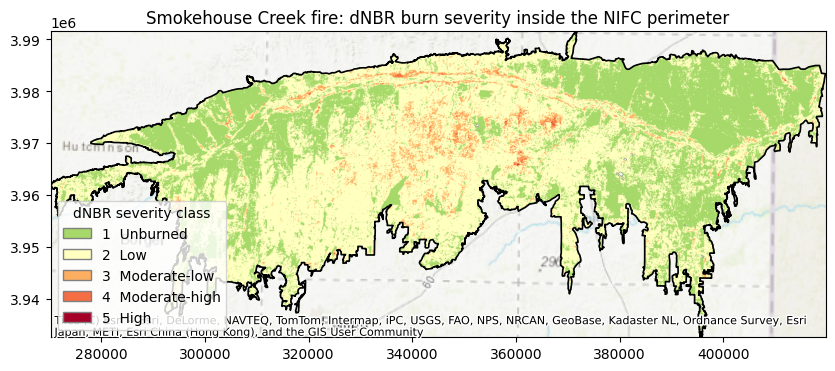

In [0]:
step("map")
import geopandas as gpd
import numpy as np
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

SEVERITY_CLASSES = [
    ("Unburned", "#a6d96a"), ("Low", "#ffffbf"), ("Moderate-low", "#fdae61"),
    ("Moderate-high", "#f46d43"), ("High", "#a50026"),
]
severity_cmap = ListedColormap([color for _, color in SEVERITY_CLASSES])
# Class k always takes colour k, whichever classes the raster holds.
severity_norm = BoundaryNorm(np.arange(0.5, 6.5, 1.0), severity_cmap.N)

severity_row = spark.sql(
    BURN_CTES.format(res=map_res_m, **burn_params)
    + "SELECT tile, gbx_rst_srid(tile) AS srid FROM severity"
).first()
fire_wkt = spark.sql(f"SELECT st_astext(geom) AS wkt FROM aois WHERE aoi_id = '{FIRE_AOI_ID}'").first()["wkt"]

ax = plot_tile(
    severity_row["tile"],
    band=1,
    cmap=severity_cmap,
    basemap_source="topo",
    title="Smokehouse Creek fire: dNBR burn severity inside the NIFC perimeter",
)
next(im for im in ax.images if im.get_zorder() == max(i.get_zorder() for i in ax.images)).set_norm(severity_norm)
ax.legend(
    handles=[Patch(facecolor=color, edgecolor="grey", label=f"{k}  {name}") for k, (name, color) in enumerate(SEVERITY_CLASSES, start=1)],
    title="dNBR severity class", loc="lower left",
)
gpd.GeoSeries.from_wkt([fire_wkt], crs=4326).to_crs(int(severity_row["srid"])).boundary.plot(
    ax=ax, color="black", linewidth=1.2
)

## 9. Ask the Genie Agents

The SQL above is what a person writes when they know the functions. A **Genie Agent** is given the same tables, the `gbx_rst_*` functions and a short set of instructions, and writes the query itself from a plain-English question, applying the method its instructions teach. The calls below use Agent mode and show the SQL each agent wrote next to its answer, so the approaches can be compared.

There are two agents over the same data and the same functions (their ids are `GENIE_SPACE_ID` and `GENIE_SPACE_ID_PRECOMPUTED` in `config_nb`):

- the **live** agent computes the whole answer from the COGs with the GeoBrix functions, so it takes one to two and a half minutes;
- the **precomputed** agent reads the saved `burn_severity_summary` table for the severity and uses the functions for everything else, so it answers well under a minute.

The SQL above counts the people inside the whole fire perimeter, burned or not, so compare the agents' population figure on that basis.

In [0]:
step("Genie Agent")
import re

from databricks.sdk import WorkspaceClient

Q3 = "How much land burned in the Smokehouse Creek fire, how severe, and how many people live inside the fire perimeter?"


def plain(text):
    """An answer without its citation links: they point into the workspace."""
    return re.sub(r"https?://\S+", "<link>", re.sub(r"\\?\[\[(\d+)\]\([^)]*\)\\?\]", r"[\1]", text))


def space_title(space_id):
    try:
        return WorkspaceClient().api_client.do("GET", f"/api/2.0/genie/spaces/{space_id}")["title"]
    except Exception:
        return "Genie space"


def ask_and_show(space_id):
    answer = ask_genie(space_id, Q3)
    print(f"== {space_title(space_id)}")
    print(f"Status:   {answer['status']} in {answer['seconds']} s")
    if answer["error"]:
        print(f"Error:    {answer['error']}")
    for i, statement in enumerate(answer["sql"], start=1):
        print(f"\n-- SQL the agent ran ({i} of {len(answer['sql'])})\n{statement}")
    print("\nAnswer:")
    for text in answer["text"]:
        print(plain(text))
    return answer


if not GENIE_SPACE_ID:
    print("... GENIE_SPACE_ID is empty in config_nb; skipping the Genie Agent step.")
    print("... Set it to the id of the raster-genie Genie space and run this cell again.")
else:
    print(f"Question: {Q3}\n")
    live = ask_and_show(GENIE_SPACE_ID)
    if GENIE_SPACE_ID_PRECOMPUTED:
        print()
        saved = ask_and_show(GENIE_SPACE_ID_PRECOMPUTED)
        print(f"\nTime to answer: live {live['seconds']} s, precomputed {saved['seconds']} s")
step("done")

... == step 11: Genie Agent (previous step 121 s, total 1,302 s)
Question: How much land burned in the Smokehouse Creek fire, how severe, and how many people live inside the fire perimeter?

== raster-genie — Smokehouse Creek (live)
Status:   COMPLETED in 151.8 s

-- SQL the agent ran (1 of 2)
WITH perimeter AS (
  SELECT geom FROM geospatial_catalog.raster_genie.aois WHERE aoi_id = 'smokehouse_creek'
),
ring AS (
  SELECT st_transform(st_difference(st_buffer(st_transform(geom, 5070), 5000),
                                    st_buffer(st_transform(geom, 5070), 1000)), 4326) AS rg
  FROM perimeter
),
meta AS (
  SELECT DISTINCT mgrs_tile, to_date(substr(date, 1, 10)) AS d, regexp_extract(item_id, '_R([0-9]+)_', 1) AS orbit
  FROM geospatial_catalog.raster_genie.s2_scene_assets
),
scenes AS (
  SELECT r.asset_id, m.mgrs_tile, m.orbit, r.acquired_date, r.bands, r.file, r.footprint
  FROM geospatial_catalog.raster_genie.rasters r
  JOIN meta m ON r.asset_id = concat('s2_', m.mgrs_tile, '

## What we built

- **`aois`** (Delta): the Smokehouse Creek perimeter, the Texas counties it touches and the Texas outline.
- **`s2_scene_assets`** (Delta): the Sentinel-2 scenes chosen, with tile, date, orbit and cloud cover.
- **`rasters`** (Delta, FILE EXTERNAL): one row per master COG, with its footprint, CRS, resolution, valid percent, band order, source and licence.
- **`coverage`** (view): what we hold per product, tier and area.
- **`burn_severity_summary`** (Delta): the severity query's answer, kept so the notebook does not read the COGs twice and so the precomputed agent can read it.
- The **burn severity** by class in acres and square kilometres, the **people** inside the perimeter, and a severity map.
- The SQL, answer and time of the live and the precomputed Genie Agent for the same question.

GeoBrix: `StacClient`, `FirePerimeterDownloader`, `WorldPopDownloader`, `prepare_cogs`, `gbx_file_write`, `gbx_rst_fromfile`, `gbx_rst_nbr`, `gbx_rst_mapalgebra`, `gbx_rst_merge`, `gbx_rst_histogram`, `gbx_rst_avg`, `gbx_rst_pixelcount`, `genie.ask`, `vizx.plot_tile`.